## v2. Boundary trial: Meso (full Mercator UVW), continuous time

Same fieldset as `Run_parcels_UVW` (monthly files, **no periodic loop**, so time is continuous over the 100 days).
Three groups of `n_per_group` particles, tracked for 100 days:

* **coast**        : wet cells touching land (lateral boundary), near surface (0-7 m)
* **shelf_bottom** : shelf columns (W bottom 20-100 m), seeded one W level above the W bottom
* **ocean_bottom** : open ocean columns (W bottom > 3000 m), seeded one W level above the W bottom

Bottom seeds: `mbathy` = number of wet T levels, so the W bottom is `depthw[mbathy]` and the seed depth is `depthw[mbathy-1]` (never below the sea bed).

Checks: deleted (crash / out of bounds), frozen, above the surface, below the W bottom, on land, clashing.

In [1]:
n_per_group = 1000
run_time_days = 100
time_step_minutes = 20
out_put_step_hours = 6

depth_min = 0      # coast group depth range
depth_max = 7

offset = 550
ref_date = "1993-01-01"
#reproducibility
rdm_seed = 16
#paths
pathUVW= '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW'
Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

# boxes (lon0, lon1, lat0, lat1) where each group is drawn
box_shelf = (-52, -44, -2, 6)     # Amazon / Para shelf
box_ocean = (-48, -40, 2, 10)     # deep ocean offshore

In [2]:
import numpy as np

In [3]:
out_path = f'tracks_boundaries_{rdm_seed}/' #path to store the particle zarr
groups = ["coast", "shelf_bottom", "ocean_bottom"]

start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
start_time

np.datetime64('1994-07-05')

In [4]:
import pandas as pd
start_time = pd.to_datetime(start_time)
t_plus_2y = start_time + pd.DateOffset(years=2)

st_yr = str(start_time)[0:4]
end_yr = str(t_plus_2y)[0:4]

print(st_yr)
print(end_yr)

1994
1996


## Particles from the ARP to the Atlantic

In [5]:
from parcels import ParticleSet
from parcels import JITParticle
from parcels import AdvectionRK4_3D
from parcels import Variable
from datetime import timedelta
from parcels import FieldSet

In [6]:
np.random.seed(rdm_seed)

In [7]:
from pathlib import Path
import os

def files_span(base, prefix, st_yr, end_yr, suffix='c.nc'):
    # all months from Jan st_yr to Dec end_yr
    months = pd.period_range(f'{st_yr}-01', f'{end_yr}-12', freq='M')
    pats = [Path(base) / f"{prefix}_{p.year}-{p.month:02d}{suffix}" for p in months]
    # keep only existing files
    return [str(p) for p in pats if p.exists()]

ufiles = files_span(pathUVW, 'U', st_yr, end_yr, 'c.nc')
vfiles = files_span(pathUVW, 'V', st_yr, end_yr, 'c.nc')
wfiles = files_span(pathUVW, 'W', st_yr, end_yr, 'fc.nc') 
# tfiles = files_span(pathTS,  'T', st_yr, end_yr, 'c.nc')
# sfiles = files_span(pathTS,  'S', st_yr, end_yr, 'c.nc')

In [8]:
## define the fieldset
filenames = {
    "U": {
        "data":ufiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "V": {
        "data": vfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "W": {
        "data": wfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
}

variables = {
    "U": "vozocrtx",
    "V": "vomecrty",
    "W": "vovecrtz",
}

interp_method = {
    "U":"cgrid_velocity",
    "V":"cgrid_velocity",
    "W":"cgrid_velocity",
}


dimensions = {
    "U": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "V": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "W": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
}


## now the fieldset
fieldset = FieldSet.from_nemo(
    filenames, 
    variables, 
    dimensions,
    # interp_method = interp_method,
    # tracer_interp_method="cgrid_tracer",
    deferred_load=True,
    allow_time_extrapolation = False,
    # gridindexingtype = "nemo",
)


## Model grid: land mask, W bottom, coast cells

In [9]:
import xarray as xr

_h = xr.open_dataset(Hgr)
_z = xr.open_dataset(Zgr)
glamt = _h.glamt.isel(t=0).values          # T points = cell centres
gphit = _h.gphit.isel(t=0).values
glamf = _h.glamf.isel(t=0).values          # f points = cell corners
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values.astype(int)   # wet T levels per column (0 = land)
depthw = xr.open_dataset(wfiles[0]).depthw.values
nz = len(depthw)

# W bottom of each column (the W level under the deepest wet T cell)
w_bottom = np.where(mbathy > 0, depthw[np.minimum(mbathy, nz - 1)], 0.0)

land = mbathy == 0
touches_land = np.zeros_like(land)
touches_land[1:-1, 1:-1] = land[:-2, 1:-1] | land[2:, 1:-1] | land[1:-1, :-2] | land[1:-1, 2:]

def in_box(b):
    return (glamt > b[0]) & (glamt < b[1]) & (gphit > b[2]) & (gphit < b[3])

kmin = int(np.searchsorted(depthw, depth_max))   # levels needed to hold depth_max
interior = np.zeros_like(land); interior[2:-2, 2:-2] = True   # stay off the domain edges

candidates = {
    "coast":        in_box(box_shelf) & interior & ~land & touches_land & (mbathy >= kmin),
    "shelf_bottom": in_box(box_shelf) & interior & ~land & ~touches_land & (w_bottom >= 20) & (w_bottom <= 100),
    "ocean_bottom": in_box(box_ocean) & interior & ~land & (w_bottom > 3000) & (mbathy < nz),
}
for g, m in candidates.items():
    print(f"{g:13s}: {m.sum()} candidate cells")

coast        : 215 candidate cells
shelf_bottom : 1495 candidate cells
ocean_bottom : 8687 candidate cells


## Seeding

In [10]:
start_lon, start_lat, start_depth, start_group = [], [], [], []
for gi, g in enumerate(groups):
    jj, ii = np.where(candidates[g])
    # reuse cells when a group has fewer cells than particles (coast has only a few hundred)
    pick = np.random.choice(len(jj), n_per_group, replace=n_per_group > len(jj))
    j, i = jj[pick], ii[pick]
    # random position inside the T cell, whose corners are f(j-1,i-1)..f(j,i)
    start_lon.append(np.random.uniform(glamf[j, i-1], glamf[j, i]))
    start_lat.append(np.random.uniform(gphif[j-1, i], gphif[j, i]))
    if g == "coast":
        start_depth.append(np.random.uniform(depth_min, depth_max, n_per_group))
    else:
        start_depth.append(depthw[mbathy[j, i] - 1])     # one W level above the W bottom
    start_group.append(np.full(n_per_group, gi))

start_lon = np.concatenate(start_lon)
start_lat = np.concatenate(start_lat)
start_depth = np.concatenate(start_depth)
start_group = np.concatenate(start_group)
num_particles = len(start_lon)
start_times = np.datetime64(start_time)

for gi, g in enumerate(groups):
    s = start_group == gi
    print(f"{g:13s}: depth {start_depth[s].min():8.2f} - {start_depth[s].max():8.2f} m")

coast        : depth     0.01 -     7.00 m
shelf_bottom : depth    19.99 -    71.56 m
ocean_bottom : depth  2696.58 -  5052.47 m


In [11]:
# sanity check: no seed below the W bottom, and none on land
from scipy.spatial import cKDTree
_tree = cKDTree(np.c_[glamt.ravel(), gphit.ravel()])

def cell_of(lon, lat):
    _, k = _tree.query(np.c_[lon, lat])
    return np.unravel_index(k, glamt.shape)

j, i = cell_of(start_lon, start_lat)
assert np.all(start_depth < w_bottom[j, i]), "some seeds are below the W bottom"
print("all seeds above the W bottom")

# Land velocities are zeroed on load, so an exactly-zero UVW means a dry cell.
fieldset.computeTimeChunk(fieldset.U.grid.time[0], 1)
_t = fieldset.U.grid.time[0]
_dry = np.array([fieldset.UVW[_t, d, la, lo] == (0.0, 0.0, 0.0)
                 for lo, la, d in zip(start_lon, start_lat, start_depth)])
print(", ".join(f"{g} {_dry[start_group == gi].sum()}/{n_per_group}" for gi, g in enumerate(groups)) + " seeded on land")
assert _dry.sum() == 0, "some particles are on land" 

all seeds above the W bottom


coast 0/1000, shelf_bottom 0/1000, ocean_bottom 0/1000 seeded on land


In [12]:
BoundaryParticle = JITParticle.add_variable(Variable("group", dtype=np.int32, to_write="once"))

pset = ParticleSet(
    fieldset=fieldset,
    pclass=BoundaryParticle,
    lon=start_lon,
    lat=start_lat,
    depth=start_depth,
    time=start_times,
    group=start_group,
)

out_fn = f'Parcels_boundaries_{rdm_seed}_{str(start_time)[:10]}.zarr'

output_file = pset.ParticleFile(
    name=out_path+out_fn,
    outputdt=timedelta(hours=out_put_step_hours),
    chunks=(num_particles, int(run_time_days*24/out_put_step_hours/4)),
)

In [13]:
##check the error: print what killed the particle, then delete it
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        print("ERROR state=%d group=%d lon=%f lat=%f z=%f" % (particle.state, particle.group, particle.lon, particle.lat, particle.depth))
        particle.delete()

In [14]:
## Execute particles
pset.execute(
    [AdvectionRK4_3D, CheckError],
    runtime=timedelta(days=run_time_days),
    dt=timedelta(minutes=time_step_minutes),
    output_file=output_file,
)

INFO: Output files are stored in tracks_boundaries_16/Parcels_boundaries_16_1994-07-05.zarr.



  0%|          | 0/8640000.0 [00:00<?, ?it/s]


  0%|          | 1200.0/8640000.0 [00:13<27:37:53, 86.85it/s]


  0%|          | 21600.0/8640000.0 [00:14<1:07:44, 2120.20it/s]


  0%|          | 43200.0/8640000.0 [00:21<56:22, 2541.48it/s]  


  1%|          | 64800.0/8640000.0 [00:22<32:34, 4386.87it/s]

... (396 outputs left out)


100%|█████████▉| 8596800.0/8640000.0 [16:02<00:06, 6390.02it/s] 


100%|█████████▉| 8618400.0/8640000.0 [16:03<00:02, 8353.51it/s]


100%|██████████| 8640000.0/8640000.0 [16:03<00:00, 10666.71it/s]


100%|██████████| 8640000.0/8640000.0 [16:03<00:00, 8964.44it/s] 

## Diagnostics

In [15]:
ds_traj = xr.open_zarr(out_path+out_fn).compute()
lon, lat, z = ds_traj.lon.values, ds_traj.lat.values, ds_traj.z.values
grp = ds_traj.group.values.astype(int)   # stored as float in the zarr
valid = ~np.isnan(lat)
n_obs = ds_traj.sizes["obs"]
days = np.arange(n_obs) * out_put_step_hours / 24

def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

# position -> model cell (nearest T point)
jj, ii = cell_of(np.nan_to_num(lon.ravel()), np.nan_to_num(lat.ravel()))
wb = np.where(valid, w_bottom[jj, ii].reshape(lon.shape), np.nan)
on_land = (mbathy[jj, ii] == 0).reshape(lon.shape) & valid
below_bed = (z > wb) & valid
above_surf = (z < 0) & valid

# frozen: never more than 50 m (horizontal) and 0.1 m (vertical) away from where it was
# at the start of a 5-day window, for the whole window
W = min(int(5 * 24 / out_put_step_hours), n_obs - 1)
dh_max = np.zeros((lon.shape[0], n_obs - W))
dz_max = np.zeros_like(dh_max)
for lag in range(1, W + 1):
    e = n_obs - W + lag
    dh_max = np.maximum(dh_max, haversine_km(lon[:, :n_obs-W], lat[:, :n_obs-W], lon[:, lag:e], lat[:, lag:e]))
    dz_max = np.maximum(dz_max, np.abs(z[:, lag:e] - z[:, :n_obs-W]))
frozen = (dh_max < 0.05) & (dz_max < 0.1)          # (trajectory, window start); NaN compares False

# clashing: two particles within 100 m and 1 m depth at the same output
# (pairs already that close at release are ignored)
def close_pairs(t):
    d = haversine_km(lon[:, None, t], lat[:, None, t], lon[None, :, t], lat[None, :, t])
    return (d < 0.1) & (np.abs(z[:, None, t] - z[None, :, t]) < 1)

close0 = close_pairs(0)
clash = np.zeros(lon.shape[0], dtype=bool)
for t in range(1, n_obs):
    clash |= (close_pairs(t) & ~close0).any(axis=1)

flags = dict(deleted=~valid[:, -1], frozen=frozen.any(axis=1), below_bed=below_bed.any(axis=1),
             above_surface=above_surf.any(axis=1), on_land=on_land.any(axis=1), clashing=clash)

rows = []
for gi, g in enumerate(groups):
    s = grp == gi
    row = {"group": g}
    row.update({k: int(v[s].sum()) for k, v in flags.items()})
    row["alive_at_end"] = int(valid[s, -1].sum())
    row["max_z [m]"] = round(float(np.nanmax(z[s])), 1)
    rows.append(row)
summary = pd.DataFrame(rows).set_index("group")
summary

,deleted,frozen,below_bed,above_surface,on_land,clashing,alive_at_end,max_z [m]
group,,,,,,,,
coast,0,2,3,0,0,14,1000,44.8
shelf_bottom,0,6,8,0,0,2,1000,199.9
ocean_bottom,0,3,7,0,0,0,1000,5181.1


In [16]:
# details of every flagged particle
for k, v in flags.items():
    for p in np.where(v)[0]:
        last = np.where(valid[p])[0][-1]
        extra = ""
        if k == "frozen":
            extra = f"frozen from day {days[np.argmax(frozen[p])]:.2f}, {frozen[p].sum()*out_put_step_hours/24:.1f} days of frozen windows"
        if k == "below_bed":
            extra = f"max {np.nanmax(z[p]-wb[p]):.1f} m below W bottom at day {days[np.nanargmax(z[p]-wb[p])]:.2f}"
        print(f"{k:13s} traj {p:2d} ({groups[grp[p]]:12s}) last valid day {days[last]:6.2f} "
              f"lon {lon[p, last]:.3f} lat {lat[p, last]:.3f} z {z[p, last]:.1f}  {extra}")

frozen        traj 398 (coast       ) last valid day  99.75 lon -48.458 lat -1.284 z 7.7  frozen from day 82.50, 1.8 days of frozen windows
frozen        traj 655 (coast       ) last valid day  99.75 lon -50.135 lat 0.458 z 7.2  frozen from day 16.25, 78.8 days of frozen windows
frozen        traj 1331 (shelf_bottom) last valid day  99.75 lon -56.479 lat 7.399 z 1.4  frozen from day 40.00, 11.2 days of frozen windows
frozen        traj 1358 (shelf_bottom) last valid day  99.75 lon -46.292 lat 0.542 z 33.0  frozen from day 13.50, 81.5 days of frozen windows
frozen        traj 1398 (shelf_bottom) last valid day  99.75 lon -45.043 lat -0.291 z 43.4  frozen from day 6.00, 89.0 days of frozen windows
frozen        traj 1608 (shelf_bottom) last valid day  99.75 lon -49.293 lat 2.543 z 8.2  frozen from day 26.25, 68.8 days of frozen windows
frozen        traj 1705 (shelf_bottom) last valid day  99.75 lon -45.390 lat -0.458 z 31.9  frozen from day 7.75, 87.2 days of frozen windows
frozen      

## Plotting

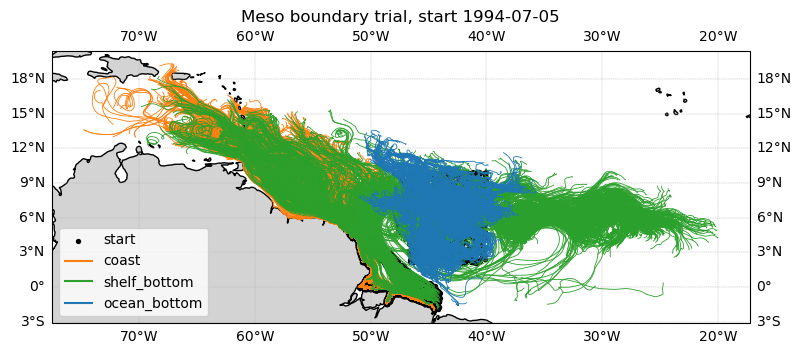

In [17]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

colors = {"coast": "tab:orange", "shelf_bottom": "tab:green", "ocean_bottom": "tab:blue"}
fig = plt.figure(figsize=(9, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.coastlines(resolution='50m')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
for p in range(num_particles):
    ax.plot(lon[p], lat[p], lw=0.6, color=colors[groups[grp[p]]], transform=ccrs.PlateCarree())
ax.scatter(start_lon, start_lat, s=8, color='k', transform=ccrs.PlateCarree(), label='start')
for g, c in colors.items():
    ax.plot([], [], color=c, label=g)
ax.legend(loc='lower left')
plt.title(f'Meso boundary trial, start {str(start_time)[:10]}')
plt.show()

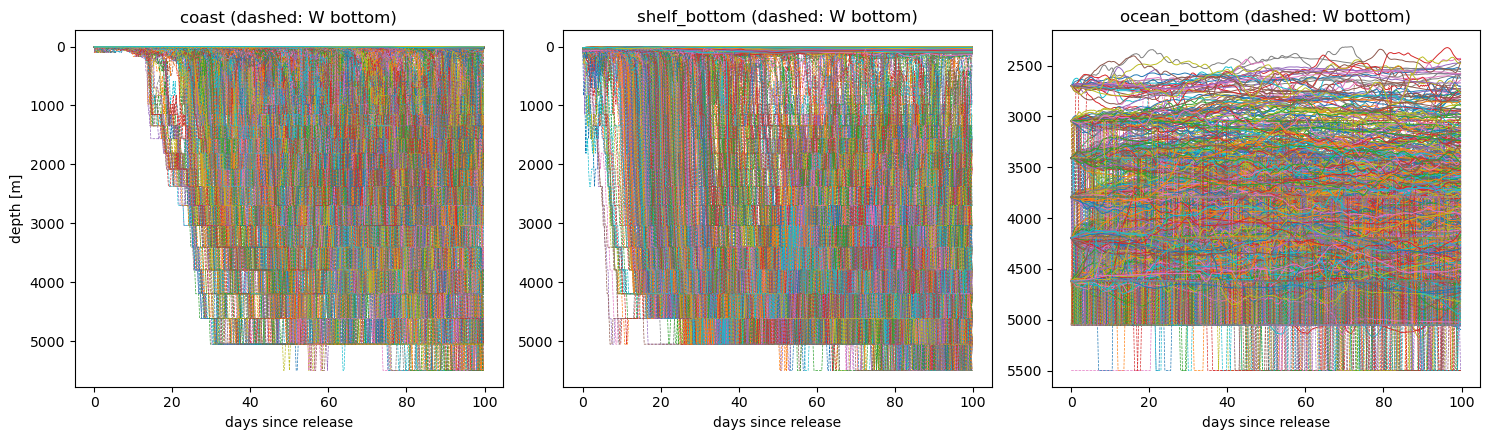

In [18]:
# depth of every particle vs the W bottom under it
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for c, g in enumerate(groups):
    ax = axes[c]
    for p in np.where(grp == c)[0]:
        l, = ax.plot(days, z[p], lw=0.7)
        ax.plot(days, wb[p], lw=0.5, ls='--', color=l.get_color())
    ax.invert_yaxis()
    ax.set_title(f"{g} (dashed: W bottom)")
    ax.set_xlabel('days since release')
axes[0].set_ylabel('depth [m]')
plt.tight_layout()
plt.show()

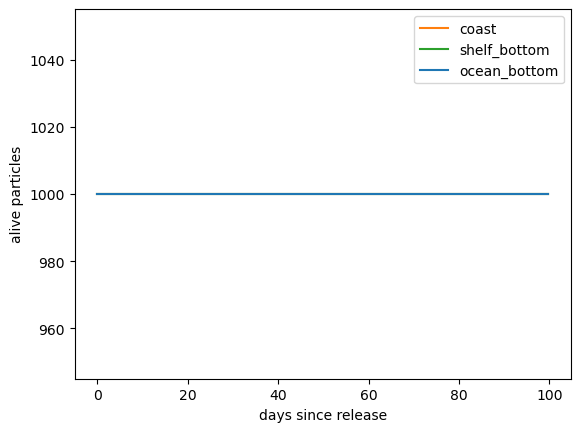

In [19]:
# particles still alive per group
for gi, g in enumerate(groups):
    plt.plot(days, valid[grp == gi].sum(axis=0), color=colors[g], label=g)
plt.ylabel('alive particles'); plt.xlabel('days since release'); plt.legend()
plt.show()